In [6]:
from script import *

In [7]:
device = "cuda"
model = ResNetUNet(num_classes=2, pretrained=True).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=255)
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
)

train_dataset = PenguinDataset("dataset/train")
valid_dataset = PenguinDataset("dataset/valid")

duplicate_train_name = (
    "00000138_jpg.rf.a0a6ee1db35ff8e042928ae5a15597d9.jpg"
)

train_indices = [
    index
    for index, info in enumerate(train_dataset.images)
    if info["file_name"] != duplicate_train_name
]

assert len(train_dataset) - len(train_indices) == 1

train_subset = Subset(train_dataset, train_indices)

train_loader = DataLoader(
    train_subset,
    batch_size=1,
    shuffle=True,
    num_workers=0,
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
)

output_dir = Path("runs/penguin_baseline")
output_dir.mkdir(parents=True, exist_ok=True)

In [8]:
trainer = Trainer(
    model,
    train_loader,
    valid_loader,
    criterion,
    optimizer,
    device,
    output_dir,
)

In [9]:
trainer.fit(10)

[logs] === epoch 01 ===
 train loss: 0.2996
 valid loss: 0.2657
 penguin iou: 0.7777

[save] === best checkpoint saved ===

[logs] === epoch 02 ===
 train loss: 0.1674
 valid loss: 0.2066
 penguin iou: 0.7738

[logs] === epoch 03 ===
 train loss: 0.1096
 valid loss: 0.1528
 penguin iou: 0.8310

[save] === best checkpoint saved ===

[logs] === epoch 04 ===
 train loss: 0.0774
 valid loss: 0.3036
 penguin iou: 0.7020

[logs] === epoch 05 ===
 train loss: 0.1339
 valid loss: 0.2064
 penguin iou: 0.7749

[logs] === epoch 06 ===
 train loss: 0.0724
 valid loss: 0.1275
 penguin iou: 0.8599

[save] === best checkpoint saved ===

[logs] === epoch 07 ===
 train loss: 0.0501
 valid loss: 0.1298
 penguin iou: 0.8675

[save] === best checkpoint saved ===

[logs] === epoch 08 ===
 train loss: 0.0396
 valid loss: 0.1203
 penguin iou: 0.8766

[save] === best checkpoint saved ===

[logs] === epoch 09 ===
 train loss: 0.0340
 valid loss: 0.1240
 penguin iou: 0.8824

[save] === best checkpoint saved ===

---

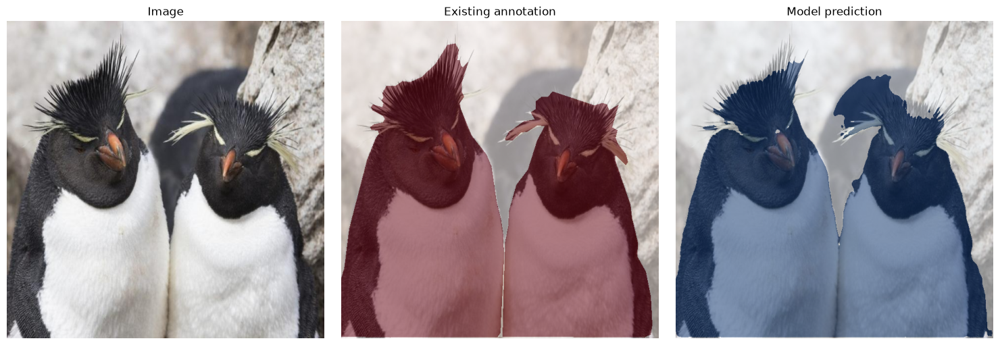

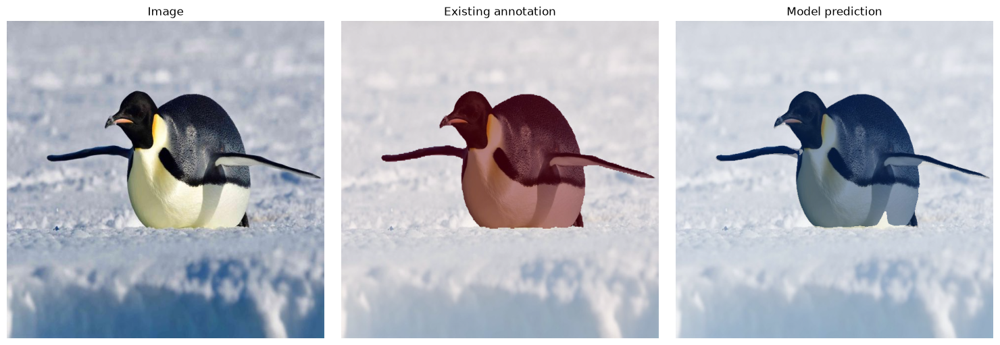

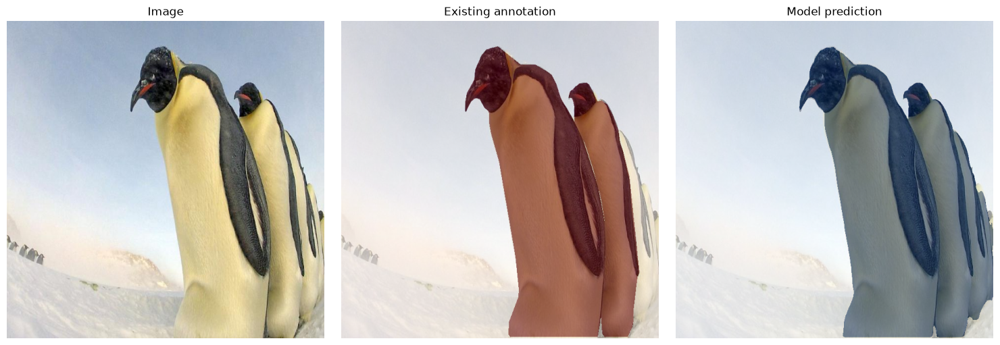

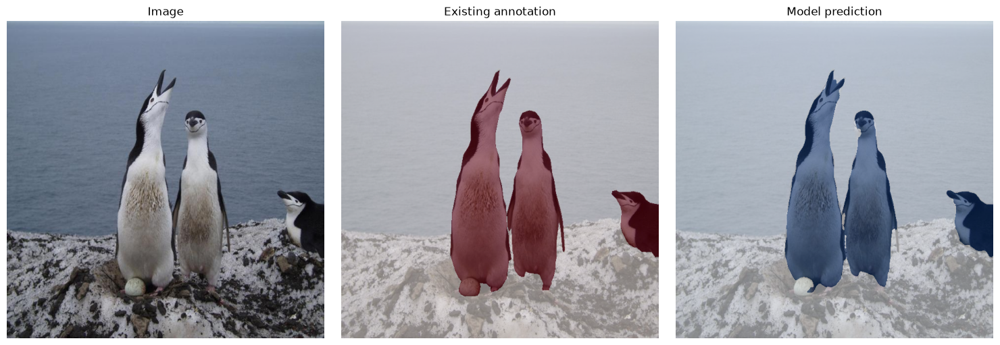

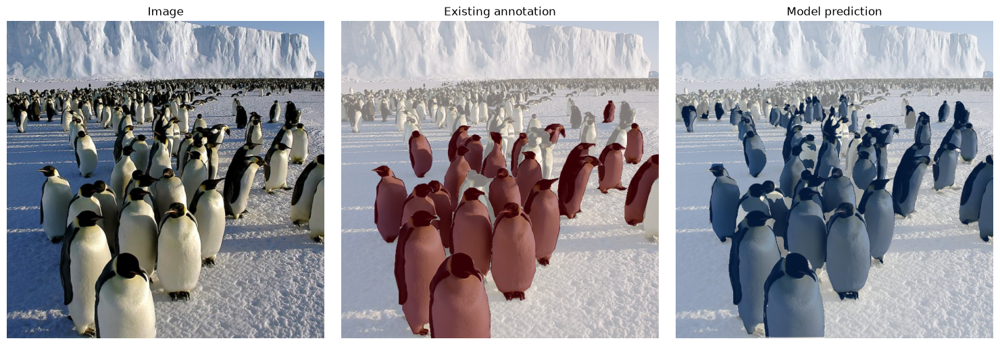

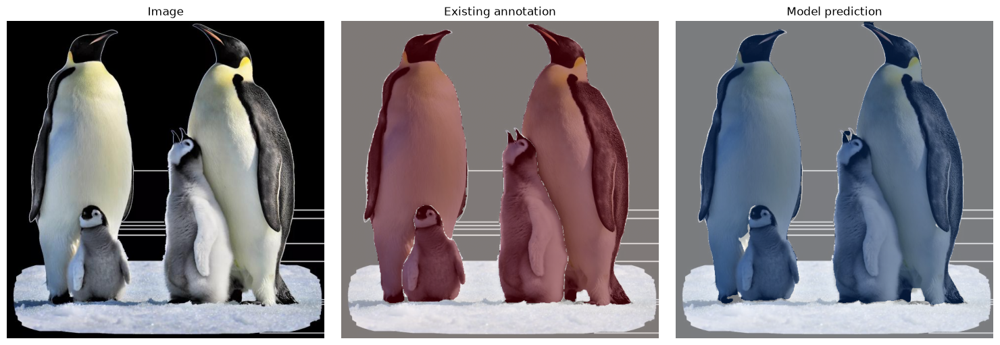

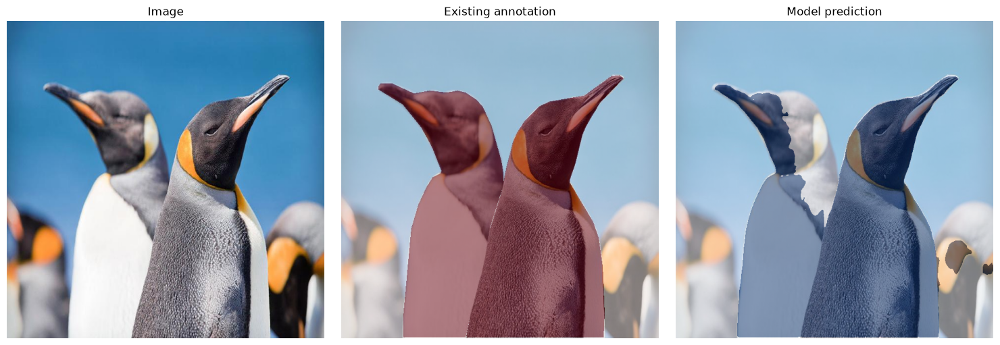

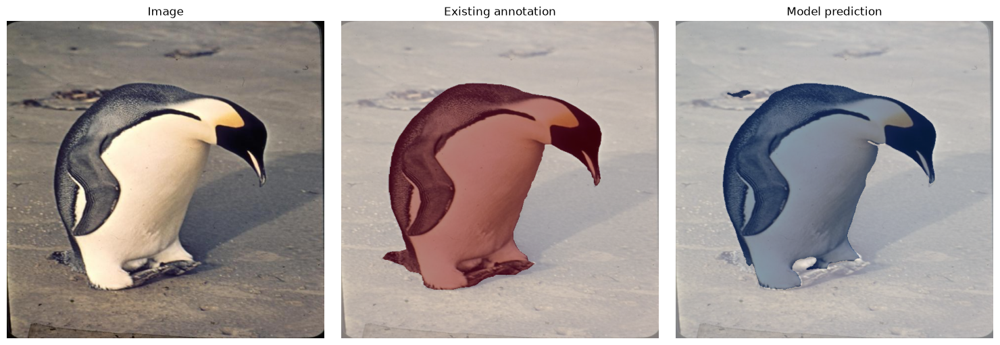

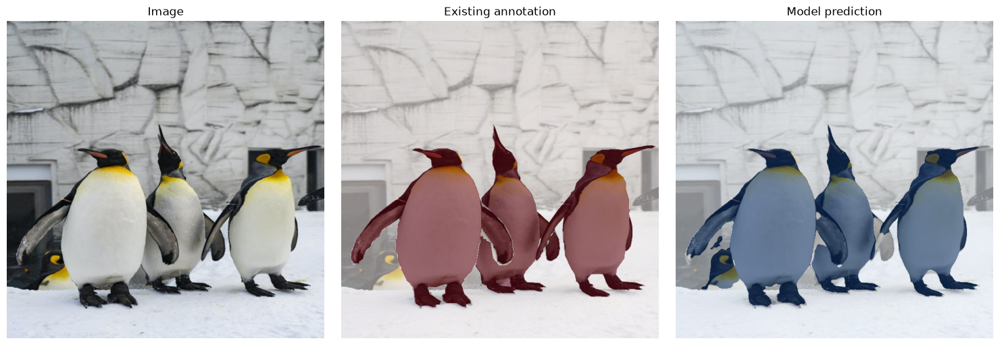

In [10]:
for index in range(9):
    show_validation_prediction(trainer.model, valid_dataset, index, device)

## Experiment 1: sliding window and whole-image resize

Each example is shown twice: one sliding-window prediction (cyan rectangles show the tiles) and one whole-image-resize prediction. These are qualitative illustrations without reference masks.

**Run only the setup and experiment cells below.** Running all notebook cells also runs `trainer.fit(10)` above, which starts training and may overwrite the checkpoint.

Public example sources: [far image](https://commons.wikimedia.org/wiki/File:Baily%27s_Head_chinstrap_penguin_colony_-_Deception_Island%2C_Antarctica.jpg) (CC BY-SA 4.0) and [near image](https://commons.wikimedia.org/wiki/File:Chinstrap_Penguin_%28Unsplash%29.jpg) (CC0).

In [2]:
from pathlib import Path
import torch

from experiment1 import load_model, run_experiment1
from experiment2 import run_experiment2

# Start the notebook from the project directory.
PROJECT_ROOT = Path.cwd()
CHECKPOINT_PATH = PROJECT_ROOT / "runs" / "penguin_baseline" / "best.pt"

EXAMPLE_PATHS = [
    PROJECT_ROOT / "examples" / "penguins_far.jpg",
    PROJECT_ROOT / "examples" / "penguins_near.jpg",
]

# private testset
TESTSET_PATHS = [
    PROJECT_ROOT / "nju_testset" / "5N0A5174_1.jpg",
    PROJECT_ROOT / "nju_testset" / "5N0A5204_1.jpg",
    PROJECT_ROOT / "nju_testset" / "5N0A5965_1.jpg",
    PROJECT_ROOT / "nju_testset" / "5N0A7706_1.jpg",
    PROJECT_ROOT / "nju_testset" / "5N0A7727_1.jpg",
    PROJECT_ROOT / "nju_testset" / "5N0A9908_1.jpg",
]

TILE_SIZE = 640
STRIDE = 480

experiment_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
experiment_model = load_model(CHECKPOINT_PATH, experiment_device)
print(f"Model loaded on: {experiment_device}")

Model loaded on: cuda


Experiment 1: penguins_far.jpg
  Number of tiles: 104
  Processed 25/104 tiles
  Processed 50/104 tiles
  Processed 75/104 tiles
  Processed 100/104 tiles


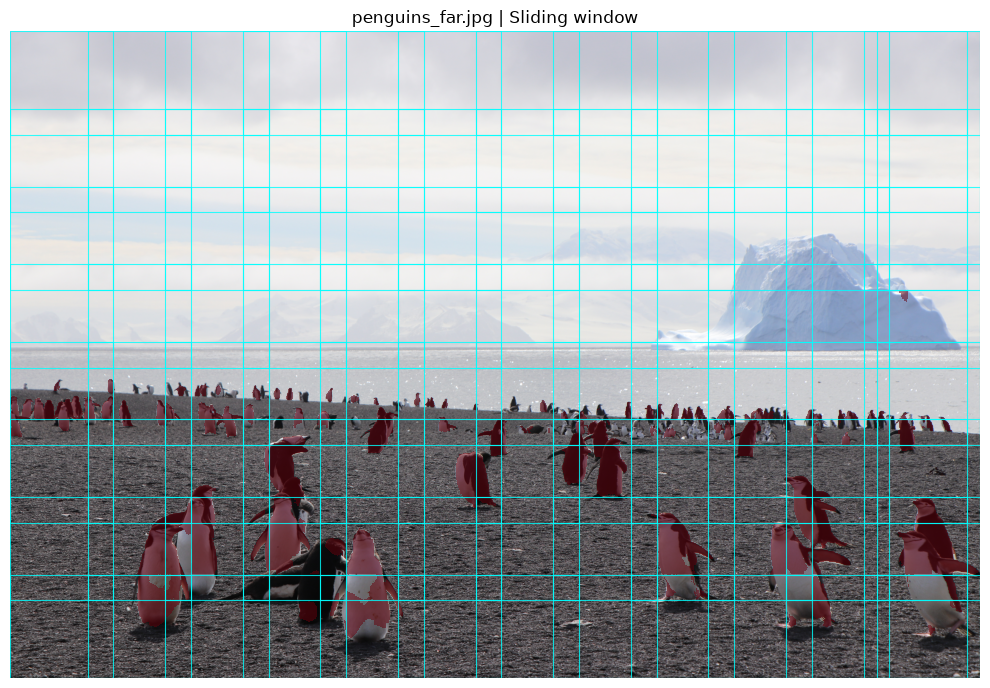

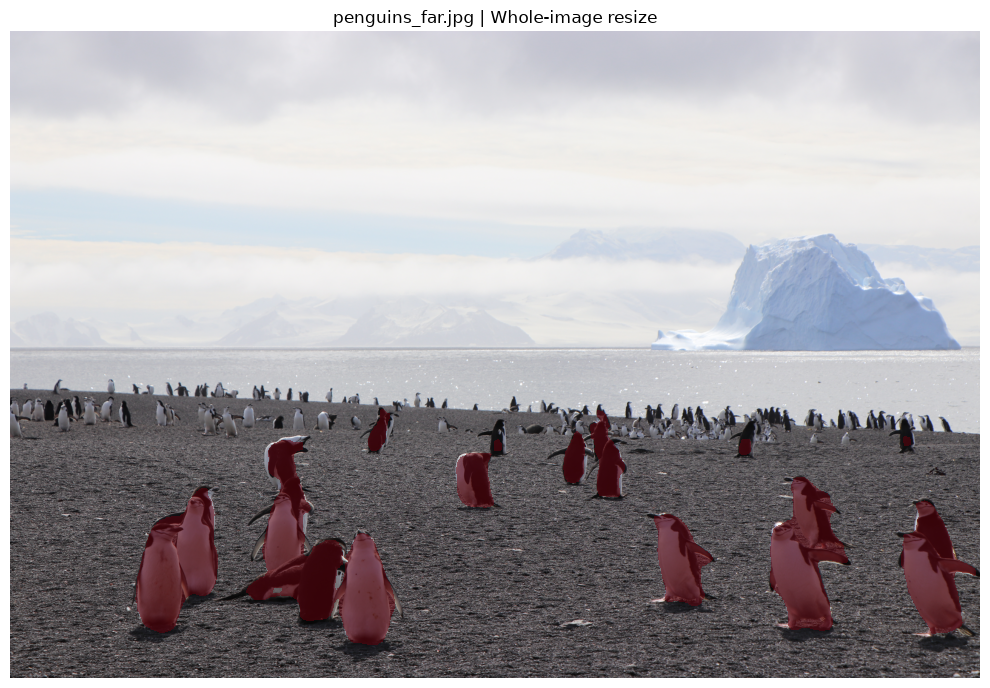

Experiment 1: penguins_near.jpg
  Number of tiles: 77
  Processed 25/77 tiles
  Processed 50/77 tiles
  Processed 75/77 tiles


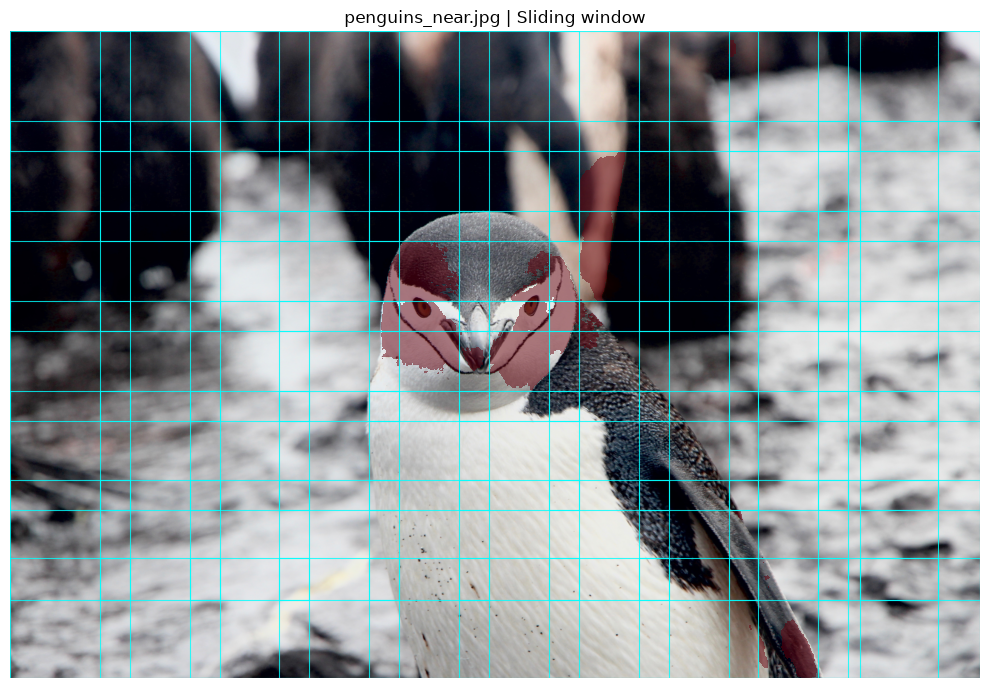

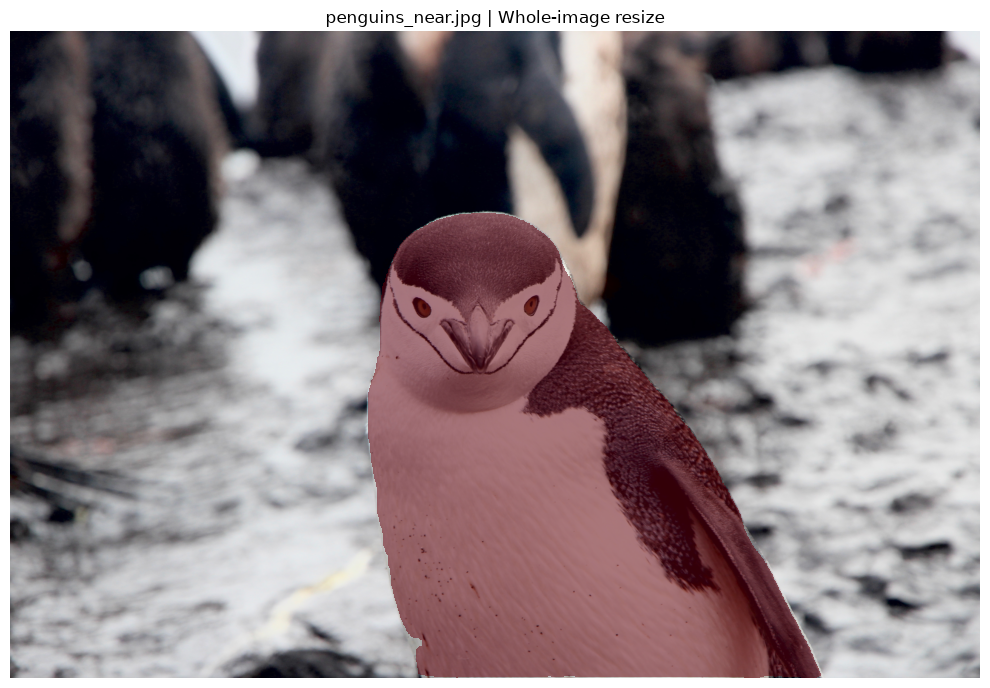

In [10]:
run_experiment1(
    model=experiment_model,
    device=experiment_device,
    image_paths=EXAMPLE_PATHS,
    tile_size=TILE_SIZE,
    stride=STRIDE,
)

## Experiment 2: global-local probability fusion

Both predictions are aligned to original-image coordinates. Their foreground probabilities are combined using the `alpha` and threshold set in the cell below. The model and checkpoint are unchanged; compare results qualitatively with experiment 1.


Experiment 2: penguins_far.jpg (6000 x 4000)
  Number of tiles: 104
  Processed 25/104 tiles
  Processed 50/104 tiles
  Processed 75/104 tiles
  Processed 100/104 tiles


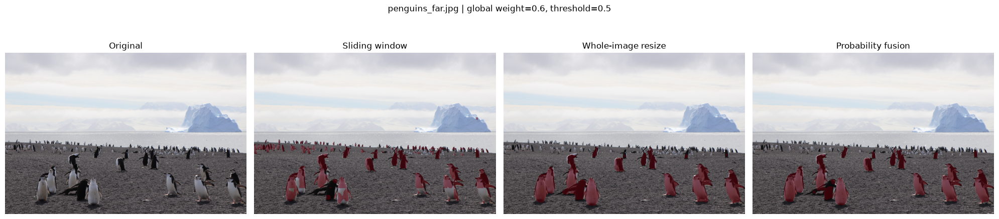

Experiment 2: penguins_near.jpg (5184 x 3456)
  Number of tiles: 77
  Processed 25/77 tiles
  Processed 50/77 tiles
  Processed 75/77 tiles


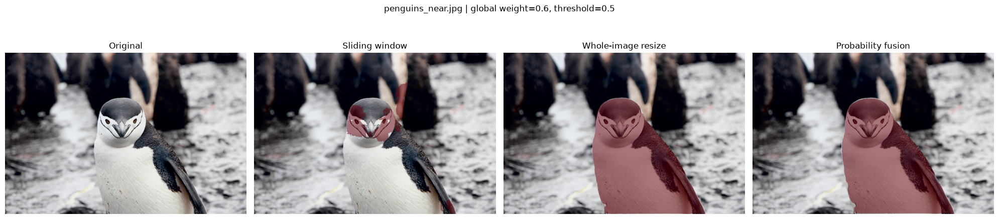

In [12]:
run_experiment2(
    model=experiment_model,
    device=experiment_device,
    image_paths=EXAMPLE_PATHS,
    tile_size=TILE_SIZE,
    stride=STRIDE,
    alpha=0.6,       # Weight for the whole-image prediction.
    threshold=0.5,
)

## Experiment 3: dual-biased probability fusion and union

Two fusion scores use different weights for the same sliding-window and whole-image predictions. Each score is thresholded separately; the final mask is their union. Both alpha values below are weights for the **whole-image resize** branch. A smaller alpha favors sliding windows; a larger alpha favors whole-image resize. Comparisons are qualitative and use the same example images and checkpoint as experiments 1 and 2.


Experiment 3: penguins_far.jpg (6000 x 4000)
  Number of tiles: 104
  Processed 25/104 tiles
  Processed 50/104 tiles
  Processed 75/104 tiles
  Processed 100/104 tiles


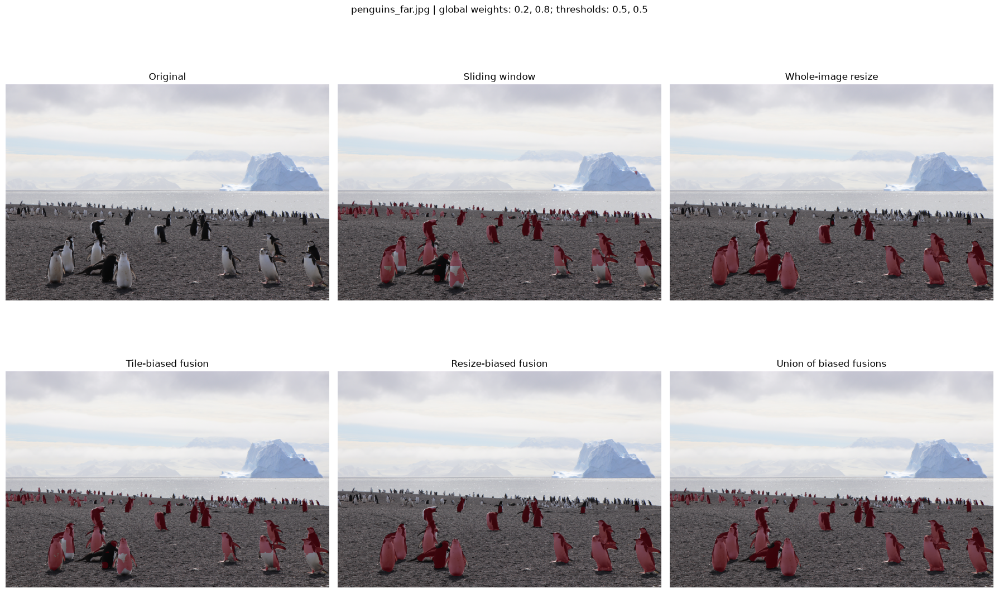

Experiment 3: penguins_near.jpg (5184 x 3456)
  Number of tiles: 77
  Processed 25/77 tiles
  Processed 50/77 tiles
  Processed 75/77 tiles


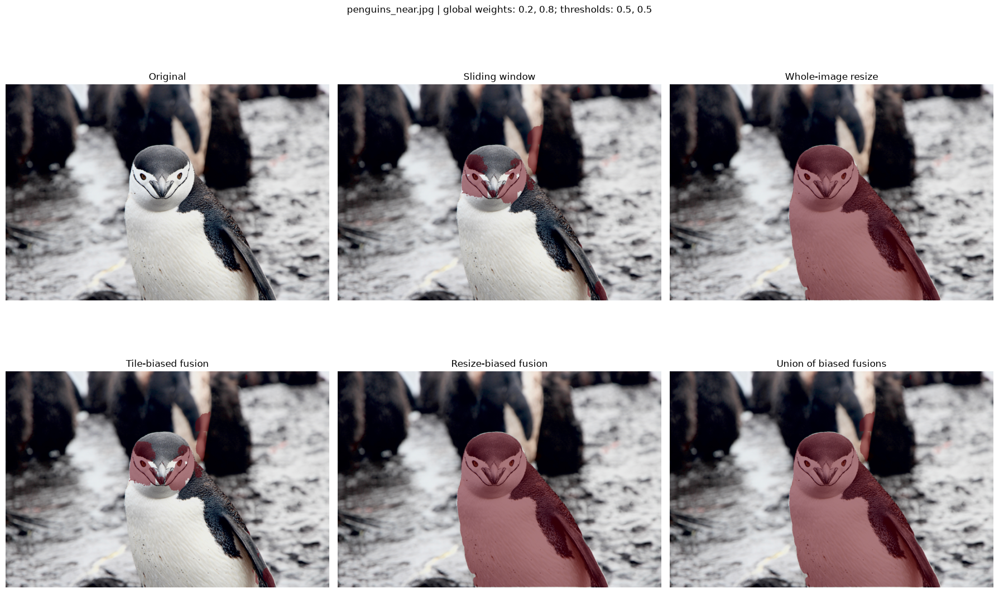

In [3]:
from experiment3 import run_experiment3

run_experiment3(
    model=experiment_model,
    device=experiment_device,
    image_paths=EXAMPLE_PATHS,
    tile_size=TILE_SIZE,
    stride=STRIDE,
    tile_bias_alpha=0.2,    # 25% resize + 75% sliding window
    global_bias_alpha=0.8,  # 75% resize + 25% sliding window
    tile_threshold=0.5,
    global_threshold=0.5,
)
